# Amharic Speech-to-Speech: Latency Optimization Track (Colab T4)

**Goal of the assignment:** minimise *End-to-End Time to First Audio* (TTFA), the time from the moment the user stops speaking to the first audible word of the answer, without making recognition, answers or speech unusable.

**What this notebook adds to the team's work.** The team notebooks already compare hohe-ASR, Ethio-ASR, tiny-aya, Gemma 3, LLAMA-Walia and OmniVoice, and measure a sequential baseline of **3.78 s** on a T4. That benchmark notes that it does *not* cover streaming, overlapped stages, prefix caching or quantization. This notebook covers exactly that:

| Stage | What is measured here |
|---|---|
| ASR | MMS-300M-WAXAL and Ethio-ASR, **with and without the Dataset.ET Amharic 5-gram language model**, plus transcribing *while the user is still speaking* (segments cut at pauses) |
| LLM | **Gemma 4 E2B** (and optionally E4B) through **llama.cpp 4-bit on the GPU** (avoids the fp16 overflow Gemma 3 hit on the T4), prompt caching, the Gemma thinking-mode and cache fixes, answer quality on 20 Amharic questions and Belebele comprehension, against the fast Llama-3.2-1B-Amharic |
| TTS | MMS-TTS with an Amharic number normaliser, OmniVoice, first-chunk vs full-sentence latency, round-trip intelligibility |
| Pipeline | an **optimization ladder**: the same models run sequential → prompt cache → streaming → 5-word first chunk → ASR during speech → LLM paused during first-chunk TTS → language model, with TTFA and the stage breakdown for each step |

**Comparable with the team benchmark:** the same 100 FLEURS `am_et` test clips (seed 42), the same text normalisation for WER/CER, and the same 200 Belebele questions.

**How to run:** `Runtime ▸ Change runtime type ▸ T4 GPU`, then `Runtime ▸ Run all`. About 45–60 minutes on a free T4 (downloads included). Results, charts and rating sheets are saved to `My Drive/Amharic_S2S_Latency/results/<run-id>/`. The last section opens a microphone demo.

## 0. Settings

In [ ]:
# ============================== RUN SETTINGS ==============================
# Edit here, then Runtime > Run all. Environment variables are only used for local testing.
import os
SMOKE_TEST   = os.environ.get("S2S_SMOKE") == "1"   # True = tiny samples, just checks the notebook runs end to end
USE_DRIVE    = os.environ.get("S2S_NO_DRIVE") != "1" # save results to Google Drive
DRIVE_FOLDER = "Amharic_S2S_Latency"

RUN_ASR, RUN_LLM, RUN_BELEBELE, RUN_TTS, RUN_E2E = True, True, True, True, True
RUN_GEMMA_DIAGNOSTICS = True                          # shows the thinking-mode and cache-reuse fixes
RUN_DEMO = os.environ.get("S2S_NO_DEMO") != "1"       # microphone demo at the end
for _k in filter(None, os.environ.get("S2S_SKIP", "").split(",")):   # local testing only, e.g. S2S_SKIP=asr,tts
    globals()["RUN_" + _k.strip().upper()] = False

# Optional heavier candidates
USE_ETHIO_ASR  = os.environ.get("S2S_NO_ETHIO") != "1"  # badrex/Ethio-ASR-amharic (2.4 GB): most accurate open Amharic ASR
USE_OMNIVOICE  = os.environ.get("S2S_NO_OMNI") != "1"   # Lab-et/omnivoice-amharic (2.5 GB): natural voice, the team's TTS
USE_GEMMA4_E4B = False                                   # unsloth/gemma-4-E4B-it-GGUF (5 GB): smarter than E2B, slower

# Sample sizes (100 FLEURS clips + seed 42 = the same clips as the team benchmark notebook)
SEED        = 42
N_FLEURS    = 4 if SMOKE_TEST else 100
N_BELEBELE  = 4 if SMOKE_TEST else 200
N_QUESTIONS = 3 if SMOKE_TEST else 20
N_E2E_TURNS = 2 if SMOKE_TEST else 20
N_TTS_FLEURS_SENTENCES = 2 if SMOKE_TEST else 20

# Pipeline settings
HANGOVER_MS       = 700   # silence that ends the user's turn (500 ms cut Amharic speakers off in the Week-6 tests)
SEG_PAUSE_MS      = 250   # a pause this long sends the speech so far to ASR while the user keeps talking
FIRST_CHUNK_WORDS = 5     # first spoken chunk = first clause mark or this many words, whichever comes first
MAX_TOKENS        = 80
MAX_SENTENCES     = 2
LM_ALPHA, LM_BETA = 0.3, 1.5          # Dataset.ET's published decoder settings
TEAM_BASELINE = dict(ttfa_s=3.78, vad_ms=400, pipeline="hohe-ASR -> tiny-aya-earth -> OmniVoice(16 steps), sequential, T4")

In [ ]:
import sys, subprocess, pathlib, time, json, platform
IN_COLAB = "google.colab" in sys.modules
ROOT = pathlib.Path("/content") if IN_COLAB else pathlib.Path(os.environ.get("S2S_ROOT", "./s2s_work")).resolve()
ROOT.mkdir(parents=True, exist_ok=True)
if IN_COLAB:
    os.environ.setdefault("HF_HOME", "/content/hf_cache")     # models on Colab's fast local disk, not in Drive
WORK = ROOT / DRIVE_FOLDER
if IN_COLAB and USE_DRIVE:
    try:
        from google.colab import drive
        drive.mount("/content/drive", timeout_ms=300000)          # approve the pop-up (all boxes) within 5 minutes
        WORK = pathlib.Path("/content/drive/MyDrive") / DRIVE_FOLDER
    except Exception as e:
        USE_DRIVE = False
        print(f"Google Drive did not mount ({e}).\n-> Continuing without Drive: results stay in /content and are zipped for "
              "download at the end.\n-> To save to Drive instead, run this cell again and click Allow in the Google pop-up.")
RUN_ID  = time.strftime("%Y%m%d-%H%M%S") + ("-smoke" if SMOKE_TEST else "")
RESULTS = WORK / "results" / RUN_ID
DATA    = ROOT / "s2s_data"
for p in (RESULTS, DATA, RESULTS / "audio"):
    p.mkdir(parents=True, exist_ok=True)
print("Colab:", IN_COLAB, "| results ->", RESULTS)
try:
    print(subprocess.run(["nvidia-smi", "--query-gpu=name,memory.total,driver_version", "--format=csv,noheader"],
                         capture_output=True, text=True).stdout.strip())
except FileNotFoundError:
    print("no NVIDIA GPU visible")

Mounted at /content/drive
Colab: True | results -> /content/drive/MyDrive/Amharic_S2S_Latency/results/20260929-185801
Tesla T4, 15360 MiB, 580.82.07


In [ ]:
# Install what Colab does not ship (~2-3 min), without changing the numpy/torch that Colab's CUDA stack is built on.
# Colab runs Python 3.13: kenlm's bundled C++ (from an old Cython) no longer compiles there, so it is regenerated first;
# pyctcdecode pins numpy<2, which pip would compile from source and downgrade Colab's numpy with, so its pin is skipped.
import importlib, importlib.util as _iu, importlib.metadata as _md, urllib.request, zipfile
PIN = ROOT / "pip_constraints.txt"
PIN.write_text("".join(f"{p}=={_md.version(p)}\n" for p in ("numpy", "torch", "torchaudio", "torchvision", "scipy", "pandas")
                       if _iu.find_spec(p)))
def pip(*args, required=True):
    r = subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-c", str(PIN), *args], capture_output=True, text=True)
    if r.returncode:
        print(f"pip install {' '.join(args)} failed:\n{(r.stdout + r.stderr)[-2500:]}")
        if required:
            raise RuntimeError("pip install failed, see the lines above")
    return r.returncode == 0
missing = [pkg for pkg, mod in [("jiwer", "jiwer"), ("uroman", "uroman"), ("onnxruntime", "onnxruntime"), ("nvidia-ml-py", "pynvml"),
                                ("soundfile", "soundfile"), ("pygtrie", "pygtrie"), ("hypothesis", "hypothesis")]
           if _iu.find_spec(mod) is None]
if missing:
    pip(*missing)
if _iu.find_spec("pyctcdecode") is None:
    pip("--no-deps", "pyctcdecode")                              # runs fine on numpy 2
HAVE_KENLM = _iu.find_spec("kenlm") is not None
if not HAVE_KENLM:
    t0 = time.time()
    src = ROOT / "kenlm-master"
    if not src.exists():
        zipfile.ZipFile(urllib.request.urlretrieve("https://github.com/kpu/kenlm/archive/master.zip")[0]).extractall(ROOT)
    HAVE_KENLM = (pip("cython", required=False)
                  and subprocess.run([sys.executable, "-m", "cython", "-3", "--cplus", "python/kenlm.pyx", "-o", "python/kenlm.cpp"],
                                     cwd=src).returncode == 0
                  and pip(str(src), required=False))
    print(f"kenlm {'built' if HAVE_KENLM else 'FAILED: continuing with greedy ASR decoding only'} ({time.time() - t0:.0f} s)")
if USE_OMNIVOICE and _iu.find_spec("omnivoice") is None and not pip("omnivoice", required=False):
    USE_OMNIVOICE = False; print("-> OmniVoice skipped, MMS-TTS only")
if RUN_DEMO and _iu.find_spec("gradio") is None and not pip("gradio", required=False):
    RUN_DEMO = False; print("-> microphone demo skipped")
importlib.invalidate_caches()
print(f"packages ready | Python {platform.python_version()} | numpy {_md.version('numpy')} | 5-gram LM: {HAVE_KENLM}")

kenlm built (95 s)
packages ready | Python 3.13.15 | numpy 2.1.3 | 5-gram LM: True


## 1. Shared utilities
Timing, GPU monitoring, the team's WER/CER normalisation, the Amharic number normaliser used before TTS, and the chunking rules used by the streaming pipeline.

In [ ]:
import re, io, gc, math, random, statistics, threading, queue, unicodedata, urllib.request, tarfile, zipfile, shutil, signal, csv, glob
import numpy as np, pandas as pd, soundfile as sf, torch, jiwer
import matplotlib.pyplot as plt
from IPython.display import display, Audio, Markdown
from huggingface_hub import hf_hub_download, snapshot_download

random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
GPU_NAME = torch.cuda.get_device_name(0) if DEVICE == "cuda" else (platform.processor() or "cpu")
ASR_DTYPE = torch.float16 if DEVICE == "cuda" else torch.float32
if DEVICE == "cpu":
    print("WARNING: no GPU. Use Runtime > Change runtime type > T4 GPU; CPU latencies are not comparable.")
print("device:", DEVICE, "|", GPU_NAME, "| torch", torch.__version__)

def sync():
    if DEVICE == "cuda": torch.cuda.synchronize()
def now(): return time.perf_counter()
def _clean(xs): return [x for x in xs if x is not None and not (isinstance(x, float) and math.isnan(x))]
def med(xs): xs = _clean(xs); return float(np.median(xs)) if xs else float("nan")
def p90(xs): xs = _clean(xs); return float(np.percentile(xs, 90)) if xs else float("nan")
def free_gpu():
    gc.collect()
    if DEVICE == "cuda": torch.cuda.empty_cache()
def vram_mb(): return torch.cuda.memory_allocated() / 2**20 if DEVICE == "cuda" else float("nan")

class GPUMonitor:
    """Samples GPU utilisation and memory in the background (NVML); includes llama.cpp's memory too."""
    def __init__(self, interval=0.05):
        self.samples, self.ok, self._stop = [], False, threading.Event()
        try:
            import pynvml; pynvml.nvmlInit()
            self.nv, self.h, self.ok = pynvml, pynvml.nvmlDeviceGetHandleByIndex(0), DEVICE == "cuda"
        except Exception:
            pass
        self.interval = interval
    def _run(self):
        while not self._stop.is_set():
            try:
                self.samples.append((self.nv.nvmlDeviceGetUtilizationRates(self.h).gpu,
                                     self.nv.nvmlDeviceGetMemoryInfo(self.h).used / 2**20))
            except Exception:
                break
            time.sleep(self.interval)
    def __enter__(self):
        if self.ok: self._t = threading.Thread(target=self._run, daemon=True); self._t.start()
        return self
    def __exit__(self, *a):
        self._stop.set()
        if self.ok: self._t.join(timeout=1)
    def summary(self):
        if not self.samples: return dict(gpu_util_mean=float("nan"), gpu_mem_peak_mb=float("nan"))
        return dict(gpu_util_mean=float(np.mean([s[0] for s in self.samples])), gpu_mem_peak_mb=float(np.max([s[1] for s in self.samples])))

# ---- WER/CER normalisation: identical to the team benchmark notebook, so numbers are comparable ----
_FOLD = {}
for _src, _dst in ((0x1210, 0x1200), (0x1280, 0x1200), (0x1220, 0x1230), (0x12D0, 0x12A0), (0x1340, 0x1338)):
    for _i in range(8): _FOLD[chr(_src + _i)] = chr(_dst + _i)
def normalize_am(t):
    t = unicodedata.normalize("NFC", str(t))
    t = re.sub(r"\[[A-Za-z]{2,4}\]", " ", t).lower()
    t = "".join(_FOLD.get(c, c) for c in t)
    t = re.sub(r"[^\w\s]|_", " ", t)
    return re.sub(r"\s+", " ", t).strip()
def wer_cer(refs, hyps):
    pairs = [(normalize_am(r), normalize_am(h) or "-") for r, h in zip(refs, hyps) if normalize_am(r)]
    if not pairs: return float("nan"), float("nan")
    R, H = zip(*pairs)
    return jiwer.wer(list(R), list(H)), jiwer.cer(list(R), list(H))

# ---- Amharic number normaliser for TTS (MMS-TTS silently drops digits) ----
_ONES = ["", "አንድ", "ሁለት", "ሶስት", "አራት", "አምስት", "ስድስት", "ሰባት", "ስምንት", "ዘጠኝ"]
_TENS = ["", "አስር", "ሃያ", "ሰላሳ", "አርባ", "ሃምሳ", "ስልሳ", "ሰባ", "ሰማንያ", "ዘጠና"]
_ABBR = {"ዓ.ም.": "ዓመተ ምሕረት", "ዓ.ም": "ዓመተ ምሕረት", "ዶ/ር": "ዶክተር", "ት/ቤት": "ትምህርት ቤት", "ኪ.ሜ.": "ኪሎ ሜትር", "ኪ.ሜ": "ኪሎ ሜትር", "%": " በመቶ"}
def _b100(n):
    t, o = divmod(n, 10)
    if t == 0: return _ONES[o]
    if t == 1: return "አስር" if o == 0 else "አስራ " + _ONES[o]
    return _TENS[t] + ("" if o == 0 else " " + _ONES[o])
def _b1000(n):
    h, r = divmod(n, 100)
    return " ".join(([_ONES[h] + " መቶ"] if h else []) + ([_b100(r)] if r else []))
def int_to_amharic(n):
    if n == 0: return "ዜሮ"
    parts = []
    for v, w in ((10**9, "ቢሊዮን"), (10**6, "ሚሊዮን"), (1000, "ሺህ")):
        c, n = divmod(n, v)
        if c: parts.append(_b1000(c) + " " + w)
    if n: parts.append(_b1000(n))
    return " ".join(parts)
def normalize_for_tts(text):
    text = re.sub(r"[*#_`]+", " ", text)                        # LLM markdown
    for a, f in _ABBR.items(): text = text.replace(a, f)
    text = re.sub(r"(?<=\d)\s*-\s*(?=\d)", " እስከ ", text)
    def _num(m):
        w = int_to_amharic(int(m.group(1).replace(",", "")))
        return w + (" ነጥብ " + " ".join(int_to_amharic(int(d)) for d in m.group(2)) if m.group(2) else "")
    text = re.sub(r"(\d{1,3}(?:,\d{3})+|\d+)(?:\.(\d+))?", _num, text)
    return re.sub(r"\s+", " ", text).strip()
assert normalize_for_tts("በ3 ሰዓት፣ 2019 ዓ.ም.") == "በሶስት ሰዓት፣ ሁለት ሺህ አስራ ዘጠኝ ዓመተ ምሕረት"

# ---- Chunking rules for streaming TTS ----
CLAUSE   = re.compile(r"[።፣፤?!፧]|\.(?=\s|$)")
SENT_END = re.compile(r"[።?!፧]|\.(?=\s|$)")
def first_chunk_end(text, cap_words):
    """First clause mark closing >= 2 words, else cut after `cap_words` words once the next word has started."""
    for m in CLAUSE.finditer(text):
        if len(text[:m.end()].split()) >= 2: return m.end()
    if cap_words:
        words = list(re.finditer(r"\S+", text))
        if len(words) > cap_words: return words[cap_words - 1].end()
    return None
def ethiopic_ratio(t):
    letters = [c for c in t if c.isalpha()]
    return sum(0x1200 <= ord(c) <= 0x139F for c in letters) / len(letters) if letters else 0.0
def resample(a, sr_from, sr_to):
    if sr_from == sr_to: return a.astype("float32")
    try:
        import librosa; return librosa.resample(a.astype("float32"), orig_sr=sr_from, target_sr=sr_to)
    except ImportError:
        x = np.linspace(0, len(a), int(len(a) * sr_to / sr_from), endpoint=False)
        return np.interp(x, np.arange(len(a)), a).astype("float32")
print("utilities ready")

device: cuda | Tesla T4 | torch 2.11.0+cu128
utilities ready


## 2. llama.cpp (GPU build) and model downloads
llama.cpp runs the LLMs as 4-bit GGUF files on the T4. It downloads a pinned prebuilt CUDA build (~20 s). If that build cannot start on this runtime's driver, it compiles from source once (~20-30 min) and keeps the binary in Drive for later sessions. Colab cannot execute programs stored in Drive, so binaries always run from the local disk.

In [ ]:
LLAMA_TAG = "b11179"            # pinned: the build this project tested Gemma 4 with
LLAMA_RT  = ROOT / "llama" / LLAMA_TAG

def _lib_dirs(root):
    dirs = {str(p.parent) for p in pathlib.Path(root).rglob("*.so*")}
    try:
        import nvidia                                   # CUDA libraries shipped with Colab's PyTorch
        for base in list(nvidia.__path__):
            dirs.update(glob.glob(os.path.join(base, "*", "lib")))
    except Exception:
        pass
    dirs.update(["/usr/local/cuda/lib64", "/usr/lib64-nvidia"])
    return ":".join(sorted(dirs) + [os.environ.get("LD_LIBRARY_PATH", "")])
def llama_env(server): return {**os.environ, "LD_LIBRARY_PATH": _lib_dirs(pathlib.Path(server).parent)}
def llama_devices(server):
    r = subprocess.run([str(server), "--list-devices"], capture_output=True, text=True, env=llama_env(server), timeout=300)
    return r.stdout + r.stderr
def _release(asset, dest):
    url = f"https://github.com/ggml-org/llama.cpp/releases/download/{LLAMA_TAG}/{asset}"
    tgz = DATA / asset
    if not tgz.exists():
        print("downloading", asset); urllib.request.urlretrieve(url, tgz)
    with tarfile.open(tgz) as tf: tf.extractall(dest)
    tgz.unlink()
def _build_from_source():
    cached = WORK / "llama_cache" / f"llama-server-{LLAMA_TAG}-cuda-sm75"
    out = LLAMA_RT / "src-build" / "llama-server"; out.parent.mkdir(parents=True, exist_ok=True)
    if not cached.exists():
        src = ROOT / "llama.cpp-src"
        if not src.exists():
            subprocess.run(["git", "clone", "--depth", "1", "--branch", LLAMA_TAG, "https://github.com/ggml-org/llama.cpp", str(src)], check=True)
        subprocess.run(["cmake", "-S", str(src), "-B", str(src / "build"), "-DGGML_CUDA=ON", "-DCMAKE_CUDA_ARCHITECTURES=75",
                        "-DBUILD_SHARED_LIBS=OFF", "-DLLAMA_CURL=OFF", "-DLLAMA_BUILD_TESTS=OFF"], check=True)
        subprocess.run(["cmake", "--build", str(src / "build"), "--config", "Release", "-j", str(os.cpu_count() or 2),
                        "--target", "llama-server"], check=True)
        cached.parent.mkdir(parents=True, exist_ok=True); shutil.copy(src / "build" / "bin" / "llama-server", cached)
    shutil.copy(cached, out); os.chmod(out, 0o755)
    return out

def setup_llama():
    if os.environ.get("S2S_LLAMA_DIR"):                       # local testing: reuse an existing build
        return pathlib.Path(os.environ["S2S_LLAMA_DIR"]) / "llama-server"
    found = next(LLAMA_RT.rglob("llama-server"), None) if LLAMA_RT.exists() else None
    if found and (DEVICE == "cpu" or "CUDA" in llama_devices(found)):
        return found
    LLAMA_RT.mkdir(parents=True, exist_ok=True)
    if DEVICE == "cpu":
        _release(f"llama-{LLAMA_TAG}-bin-ubuntu-x64.tar.gz", LLAMA_RT)
        return next(LLAMA_RT.rglob("llama-server"))
    _release(f"llama-{LLAMA_TAG}-bin-ubuntu-cuda-12.8-x64.tar.gz", LLAMA_RT)
    server = next(LLAMA_RT.rglob("llama-server"))
    if "CUDA" not in llama_devices(server):
        print("CUDA not visible to the prebuilt binary; adding its CUDA runtime package (~600 MB)")
        _release(f"cudart-llama-{LLAMA_TAG}-bin-ubuntu-cuda-12.8-x64.tar.gz", LLAMA_RT)
    if "CUDA" not in llama_devices(server):
        print("prebuilt build still cannot use the GPU on this runtime -> compiling from source (one time, ~20-30 min)")
        server = _build_from_source()
    return server

LLAMA_SERVER = setup_llama()
print("llama-server:", LLAMA_SERVER)
print(llama_devices(LLAMA_SERVER).strip().splitlines()[-3:])

downloading llama-b11179-bin-ubuntu-cuda-12.8-x64.tar.gz


/tmp/ipykernel_1205/3726292853.py:23: DeprecationWarning: Python 3.14 will, by default, filter extracted tar archives and reject files or modify their metadata. Use the filter argument to control this behavior.
  with tarfile.open(tgz) as tf: tf.extractall(dest)


llama-server: /content/llama/b11179/llama-b11179/llama-server
['Available devices:', '  CUDA0: Tesla T4 (14912 MiB, 14807 MiB free)', '0.00.000.361 I srv  llama_server: initializing ...']


In [ ]:
# ---- Model files (all open, no login needed) ----
ASR_MODELS = {"mms-300m-waxal": "waxal-benchmarking/mms-300m-waxal-amh"}
if USE_ETHIO_ASR: ASR_MODELS["ethio-asr-amharic"] = "badrex/Ethio-ASR-amharic"
LLMS = {
    "llama-3.2-1b-amharic": dict(repo="mradermacher/Llama-3.2-1B-Amharic-Instruct-GGUF", file="Llama-3.2-1B-Amharic-Instruct.Q4_K_M.gguf", extra=[]),
    # Gemma 4: its chat template turns on hidden English "thinking" unless disabled, and its sliding-window
    # attention disables prompt-cache reuse unless --swa-full is set (~10 s of re-prefill per turn on a CPU).
    "gemma-4-e2b": dict(repo="unsloth/gemma-4-E2B-it-GGUF", file="gemma-4-E2B-it-Q4_K_M.gguf",
                        extra=["--chat-template-kwargs", '{"enable_thinking": false}', "--swa-full"]),
}
if USE_GEMMA4_E4B:
    LLMS["gemma-4-e4b"] = dict(repo="unsloth/gemma-4-E4B-it-GGUF", file="gemma-4-E4B-it-Q4_K_M.gguf", extra=LLMS["gemma-4-e2b"]["extra"])
MAIN_LLM = "gemma-4-e4b" if USE_GEMMA4_E4B else "gemma-4-e2b"
FAST_LLM = "llama-3.2-1b-amharic"

t0 = now()
ASR_PATHS = {k: pathlib.Path(snapshot_download(r, allow_patterns=["*.json", "*.safetensors", "*.txt"])) for k, r in ASR_MODELS.items()}
KENLM = hf_hub_download("snapwre/amharic-asr-benchmark", "kenlm/am-5gram-aggressive.bin", repo_type="dataset")
for k, v in LLMS.items(): v["path"] = hf_hub_download(v["repo"], v["file"])
MMS_TTS_PATH = pathlib.Path(snapshot_download("facebook/mms-tts-amh", allow_patterns=["*.json", "*.safetensors"]))
VAD_ONNX = DATA / "silero_vad.onnx"
if not VAD_ONNX.exists():
    urllib.request.urlretrieve("https://github.com/snakers4/silero-vad/raw/master/src/silero_vad/data/silero_vad.onnx", VAD_ONNX)
print(f"downloads ready in {now() - t0:.0f} s")
for k, v in LLMS.items(): print(f"  {k}: {os.path.getsize(v['path']) / 1e9:.2f} GB")

# ---- Silero VAD: speech regions of an utterance, the pause structure the streaming pipeline uses ----
import onnxruntime as ort
_so = ort.SessionOptions(); _so.intra_op_num_threads = 1; _so.inter_op_num_threads = 1
VAD = ort.InferenceSession(str(VAD_ONNX), sess_options=_so, providers=["CPUExecutionProvider"])
FRAME = 512
def speech_regions(audio, sr=16000, min_gap_ms=SEG_PAUSE_MS, thr=0.5):
    """[(start_s, end_s)] of speech, merging gaps shorter than min_gap_ms (pauses at least that long split regions)."""
    state, ctx, flags = np.zeros((2, 1, 128), np.float32), np.zeros(64, np.float32), []
    for i in range(0, len(audio) - FRAME + 1, FRAME):
        f = audio[i:i + FRAME].astype(np.float32)
        out, state = VAD.run(None, {"input": np.concatenate([ctx, f])[None], "state": state, "sr": np.array(sr, np.int64)})
        ctx = f[-64:]; flags.append(out[0][0] > thr)
    fs, regions, start = FRAME / sr, [], None
    for k, s in enumerate(flags + [False]):
        if s and start is None: start = k
        if not s and start is not None: regions.append([start * fs, k * fs]); start = None
    merged = []
    for r in regions:
        if merged and r[0] - merged[-1][1] < min_gap_ms / 1000: merged[-1][1] = r[1]
        else: merged.append(r)
    return [tuple(r) for r in merged] or [(0.0, len(audio) / sr)]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 7 files:   0%|          | 0/7 [00:00<?, ?it/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 7 files:   0%|          | 0/7 [00:00<?, ?it/s]

kenlm/am-5gram-aggressive.bin: reconstructing file:   0%|          |  0.00B /  538MB            

kenlm/am-5gram-aggressive.bin: downloading bytes:           |  0.00B            

... (3 outputs left out)

gemma-4-E2B-it-Q4_K_M.gguf: downloading bytes:           |  0.00B            

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 5 files:   0%|          | 0/5 [00:00<?, ?it/s]

downloads ready in 122 s
  llama-3.2-1b-amharic: 0.83 GB
  gemma-4-e2b: 3.11 GB


## 3. Test data
* **FLEURS `am_et` test** (read speech): 100 clips sampled exactly like the team benchmark (seed 42), plus a noisy copy at 10 dB SNR.
* **20 conversational Amharic questions** covering everyday topics, places, Ethiopian names, numbers and dates, local terms and Amharic-English mixing. Each has keywords a correct answer should contain (a rough automatic check; the exported rating sheet is the real judge).
* **Belebele `amh_Ethi`**: the same 200 reading-comprehension questions as the team benchmark.
* **Your own recordings (optional):** put `*.wav` files and a `transcripts.csv` (`file,text`) in `My Drive/Amharic_S2S_Latency/my_turns/` and the end-to-end section uses them instead of synthesised questions.

In [ ]:
# ---- FLEURS: same sampling code as the team notebook -> same clips ----
def read_fleurs_tsv(split="test"):
    tsv = hf_hub_download("google/fleurs", f"data/am_et/{split}.tsv", repo_type="dataset")
    rows = []
    with open(tsv, encoding="utf-8", newline="") as f:
        for r in csv.reader(f, delimiter="\t", quoting=csv.QUOTE_NONE):
            if len(r) >= 4: rows.append(dict(sent_id=r[0], file=r[1], raw=r[2], norm=r[3]))
    return rows
FLEURS_ROWS = read_fleurs_tsv()
FLEURS_PICK = random.Random(SEED).sample(FLEURS_ROWS, min(N_FLEURS, len(FLEURS_ROWS)))
_tar = hf_hub_download("google/fleurs", "data/am_et/audio/test.tar.gz", repo_type="dataset")
_want, _audio = {r["file"] for r in FLEURS_PICK}, {}
with tarfile.open(_tar, "r:gz") as tf:
    for m in tf:
        b = os.path.basename(m.name)
        if b in _want and m.isfile():
            a, sr = sf.read(io.BytesIO(tf.extractfile(m).read()), dtype="float32")
            _audio[b] = resample(a.mean(1) if a.ndim > 1 else a, sr, 16000)
            if len(_audio) == len(_want): break
_rng = np.random.default_rng(SEED)
def add_noise(a, snr_db):
    p = np.mean(a ** 2) + 1e-12
    return (a + _rng.standard_normal(len(a)) * np.sqrt(p / (10 ** (snr_db / 10)))).astype("float32")
ASR_ITEMS = []
for i, r in enumerate(FLEURS_PICK):
    if r["file"] not in _audio: continue
    a = _audio[r["file"]]
    ASR_ITEMS.append(dict(id=f"{i:04d}", condition="fleurs_clean", audio=a, ref=r["norm"] or r["raw"]))
    ASR_ITEMS.append(dict(id=f"{i:04d}n", condition="fleurs_noisy_snr10", audio=add_noise(a, 10), ref=r["norm"] or r["raw"]))
print(len(ASR_ITEMS), "ASR items,", f"{sum(len(x['audio']) for x in ASR_ITEMS) / 16000 / 60:.1f} min of audio")

# ---- Conversational questions: (question, category, keywords a correct answer should contain) ----
QUESTIONS = pd.DataFrame([
    ("ሰላም፣ እንዴት ነህ?", "greeting", ["ሰላም", "ደህና"]),
    ("የአፍሪካ ህብረት ዋና መሥሪያ ቤት የት ነው?", "fact", ["አዲስ አበባ"]),
    ("አንድ ሳምንት ስንት ቀን ነው?", "number", ["ሰባት", "7"]),
    ("ቡና እንዴት ይፈላል?", "everyday", ["ጀበና", "ቆል", "ፈጭ", "ውሃ", "አፍል"]),
    ("ለጉንፋን ምን ማድረግ ይሻላል?", "health", ["እረፍት", "ፈሳሽ", "ውሃ", "ሐኪም", "ሀኪም"]),
    ("ዝናብ ሲዘንብ ምን መልበስ አለብኝ?", "everyday", ["ጃንጥላ", "ዝናብ ልብስ", "ኮት", "ጃኬት"]),
    ("ለፈተና በደንብ ለማጥናት ምን ላድርግ?", "everyday", ["እቅድ", "ጥና", "ተለማመ", "እረፍት", "ጊዜ"]),
    ("የኢትዮጵያ ትልቁ ሐይቅ የትኛው ነው?", "place", ["ጣና"]),
    ("ላሊበላ የሚገኘው በየትኛው ክልል ነው?", "place", ["አማራ"]),
    ("ከአዲስ አበባ ወደ ባህር ዳር እንዴት መሄድ እችላለሁ?", "place", ["አውቶቡስ", "አውሮፕላን", "በረራ", "መኪና"]),
    ("ኃይሌ ገብረሥላሴ ማን ነው?", "name", ["ሯጭ", "አትሌት", "ሩጫ"]),
    ("አበበ ቢቂላ ማን ነው?", "name", ["ማራቶን", "ሯጭ", "አትሌት", "ኦሊምፒክ"]),
    ("ሃያ አምስት ሲደመር አስራ አምስት ስንት ነው?", "number", ["አርባ", "40"]),
    ("እንቁጣጣሽ በየትኛው ወር ይከበራል?", "date", ["መስከረም"]),
    ("ከጠዋቱ ሶስት ሰዓት በፈረንጅ አቆጣጠር ስንት ሰዓት ነው?", "time", ["ዘጠኝ", "9"]),
    ("ጤፍ ምንድን ነው?", "local", ["እህል", "እንጀራ"]),
    ("የመስቀል በዓል እንዴት ይከበራል?", "local", ["ደመራ"]),
    ("bank account እንዴት መክፈት እችላለሁ?", "code_switch", ["ባንክ", "መታወቂያ", "ቅጽ", "ፎርም"]),
    ("ስልኬን ከ WiFi ጋር እንዴት ላገናኘው?", "code_switch", ["ሴቲንግ", "setting", "ቅንብር", "የይለፍ ቃል", "ፓስዎርድ", "password"]),
    ("ዓባይ ወንዝ የሚነሳው ከየት ነው?", "place", ["ጣና", "ግሽ"]),
], columns=["question", "category", "keywords"]).head(N_QUESTIONS)
SYSTEM = ("አንተ በአማርኛ የምትናገር አጋዥ የድምፅ ረዳት ነህ። ለጥያቄው በቀጥታና በአጭሩ፣ በአንድ ወይም በሁለት ዓረፍተ ነገሮች ብቻ መልስ። "
          "ዝርዝር ወይም ቁጥር ያላቸው ነጥቦች አትጠቀም።")
EXAMPLES = [("ሰላም፣ እንዴት ነህ?", "ሰላም! ደህና ነኝ፣ አመሰግናለሁ። ምን ልርዳዎት?"),
            ("የኢትዮጵያ ዋና ከተማ ማን ናት?", "የኢትዮጵያ ዋና ከተማ አዲስ አበባ ናት።")]
def chat_messages(question):
    m = [{"role": "system", "content": SYSTEM}]
    for q, a in EXAMPLES: m += [{"role": "user", "content": q}, {"role": "assistant", "content": a}]
    return m + [{"role": "user", "content": question}]
def keyword_hit(reply, keywords): return any(k.lower() in reply.lower() for k in keywords)

# ---- Belebele amh_Ethi: same subset and prompt as the team notebook ----
BELEBELE_INSTR = "Read the passage and answer the multiple-choice question. Reply with only the letter A, B, C or D."
def load_belebele(n):
    z = DATA / "Belebele.zip"
    if not z.exists(): urllib.request.urlretrieve("https://dl.fbaipublicfiles.com/belebele/Belebele.zip", z)
    with zipfile.ZipFile(z) as zf:
        name = next(x for x in zf.namelist() if x.endswith("amh_Ethi.jsonl"))
        rows = [json.loads(l) for l in zf.read(name).decode("utf-8").splitlines() if l.strip()]
    random.Random(SEED).shuffle(rows)
    return rows[:n]
def belebele_prompt(r):
    opts = "\n".join(f"{l}. {r['mc_answer' + str(i + 1)]}" for i, l in enumerate("ABCD"))
    return f"{BELEBELE_INSTR}\n\nPassage: {r['flores_passage']}\n\nQuestion: {r['question']}\n\n{opts}\n\nAnswer:"
BELEBELE = load_belebele(N_BELEBELE) if RUN_BELEBELE else []

# ---- TTS stress sentences (names, places, numbers, dates, code-switching) + FLEURS sentences ----
TTS_SENTENCES = pd.DataFrame([
    ("greeting", "ሰላም! እንዴት ልረዳዎት እችላለሁ?"),
    ("names_places", "ዶክተር አበበ በቀለ ነገ ከሰዓት በኋላ በባህር ዳር ዩኒቨርሲቲ ስለ ጤና አጠባበቅ ንግግር ያደርጋሉ።"),
    ("digits_date", "ስብሰባው መስከረም 15 ቀን 2019 ዓ.ም. በ3 ሰዓት ይጀምራል።"),
    ("code_switch", "የእርስዎ meeting ነገ በ Zoom ላይ ይካሄዳል፣ link ን በ email እልክልዎታለሁ።"),
    ("weather", "ዛሬ የአየር ሁኔታው ፀሐያማ ነው፣ ነገር ግን ምሽት ላይ ዝናብ ሊኖር ይችላል።"),
], columns=["category", "text"])
_fl = [r for r in FLEURS_ROWS if 40 <= len(r["raw"]) <= 200]
TTS_SENTENCES = pd.concat([TTS_SENTENCES, pd.DataFrame([("fleurs", r["raw"]) for r in random.Random(SEED + 1).sample(_fl, N_TTS_FLEURS_SENTENCES)],
                                                       columns=["category", "text"])], ignore_index=True)
print(f"{len(QUESTIONS)} questions | {len(BELEBELE)} Belebele items | {len(TTS_SENTENCES)} TTS sentences")

test.tsv:   0%|          | 0.00/392k [00:00<?, ?B/s]

data/am_et/audio/test.tar.gz: reconstructing file:   0%|          |  0.00B /  278MB            

data/am_et/audio/test.tar.gz: downloading bytes:           |  0.00B            

200 ASR items, 37.0 min of audio
20 questions | 200 Belebele items | 25 TTS sentences


## 4. ASR benchmark
For every model: WER/CER and latency on clean and noisy FLEURS with **greedy decoding** (what the team measured) and with the **Dataset.ET 5-gram language model** (beam search, alpha 0.3, beta 1.5). For clean clips it also transcribes the audio **in pieces cut at 250 ms pauses**, the way the streaming pipeline does while the user is still talking, to show whether that costs accuracy.

In [ ]:
def dtype_kw(dt):
    import transformers
    from packaging import version
    new = version.parse(transformers.__version__.split("+")[0]) >= version.parse("4.56.0")
    return {"dtype" if new else "torch_dtype": dt}

class CtcAsr:
    def __init__(self, name, path):
        from transformers import AutoModelForCTC, AutoProcessor
        from pyctcdecode import build_ctcdecoder
        t = now()
        self.name = name
        self.proc = AutoProcessor.from_pretrained(path)
        self.model = AutoModelForCTC.from_pretrained(path, **dtype_kw(ASR_DTYPE)).to(DEVICE).eval()
        toks = self.proc.tokenizer.convert_ids_to_tokens(list(range(self.model.config.vocab_size)))
        pad = self.proc.tokenizer.pad_token            # one label per output position (MMS's vocab file repeats an id)
        self.lm = (build_ctcdecoder(["" if x == pad else " " if x == "|" else (x or "?") for x in toks], KENLM, alpha=LM_ALPHA, beta=LM_BETA)
                   if HAVE_KENLM else None)
        sync(); self.load_s = now() - t; self.vram_mb = vram_mb()
        self.params_m = sum(p.numel() for p in self.model.parameters()) / 1e6
        t = now(); self.transcribe(np.zeros(16000, np.float32)); self.cold_ms = (now() - t) * 1e3
        self.transcribe(np.zeros(16000, np.float32), use_lm=False)
    def logprobs(self, audio):
        t0 = now()
        inp = self.proc(audio, sampling_rate=16000, return_tens
    ASR_CLIPS, ASR_SUMMARY, ASR_META = pd.concat(ASR_CLIPS), pd.concat(ASR_SUMMARY, ignore_index=True), pd.DataFrame(ASR_META)
    # Sanity check against the team notebook (same clips, greors="pt")
        inp = {k: (v.to(DEVICE, dtype=ASR_DTYPE) if v.is_floating_point() else v.to(DEVICE)) for k, v in inp.items()}
        t1 = now()
        with torch.inference_mode():
            logits = self.model(**inp).logits
        lp = torch.log_softmax(logits[0].float(), -1).cpu().numpy(); sync()
        return lp, (t1 - t0) * 1e3, (now() - t1) * 1e3
    def decode(self, lp, use_lm):
        t = now()
        text = self.lm.decode(lp) if use_lm and self.lm is not None else self.proc.batch_decode([lp.argmax(-1).tolist()])[0]
        return text.strip(), (now() - t) * 1e3
    def transcribe(self, audio, use_lm=True):
        lp, a, b = self.logprobs(audio); text, c = self.decode(lp, use_lm)
        return text, a + b + c
    def unload(self):
        del self.model; free_gpu()

def stream_cuts(audio, sr=16000):
    """Pieces the live pipeline would send to ASR: each speech region is cut SEG_PAUSE_MS after it ends.
    Returns [(start_sample, end_sample, time_the_cut_happens_s)] and the time of the last speech."""
    regs = speech_regions(audio, sr)
    cuts, prev = [], 0
    for s, e in regs:
        end = min(len(audio), int((e + SEG_PAUSE_MS / 1000) * sr))
        if end > prev: cuts.append((prev, end, end / sr)); prev = end
    return cuts, regs[-1][1]

def bench_asr(asr):
    rows = []
    with GPUMonitor() as mon:
        for it in ASR_ITEMS:
            a = it["audio"]; dur = len(a) / 16000
            lp, prep, fwd = asr.logprobs(a)
            g, g_ms = asr.decode(lp, False); l, l_ms = asr.decode(lp, True)
            row = dict(model=asr.name, id=it["id"], condition=it["condition"], audio_s=dur, ref=it["ref"],
                       prep_ms=prep, fwd_ms=fwd, greedy_dec_ms=g_ms, lm_dec_ms=l_ms, hyp_greedy=g, hyp_lm=l)
            if it["condition"].endswith("clean"):
                cuts, _ = stream_cuts(a); texts, seg_ms = [], []
                for s, e, _t in cuts:
                    t, ms = asr.transcribe(a[s:e], True); texts.append(t); seg_ms.append(ms)
                row.update(hyp_segmented=" ".join(texts), n_segments=len(cuts), last_segment_ms=seg_ms[-1])
            rows.append(row)
    df = pd.DataFrame(rows)
    summ = []
    for cond, d in df.groupby("condition"):
        for dec, hyp, dec_ms in (("greedy", "hyp_greedy", "greedy_dec_ms"), ("5-gram LM", "hyp_lm", "lm_dec_ms"))[:1 if asr.lm is None else 2]:
            total = d.prep_ms + d.fwd_ms + d[dec_ms]
            w, c = wer_cer(d.ref, d[hyp])
            summ.append(dict(model=asr.name, condition=cond, decoder=dec, n=len(d), WER=w, CER=c, latency_ms_med=med(total),
                             latency_ms_p90=p90(total), RTF_med=med(total / 1000 / d.audio_s), decode_ms_med=med(d[dec_ms])))
        if "hyp_segmented" in d and d.hyp_segmented.notna().any():
            w, c = wer_cer(d.ref, d.hyp_segmented.fillna(""))
            summ.append(dict(model=asr.name, condition=cond, decoder=("greedy" if asr.lm is None else "5-gram LM") + ", cut at pauses", n=len(d), WER=w, CER=c,
                             latency_ms_med=med(d.last_segment_ms), latency_ms_p90=p90(d.last_segment_ms), RTF_med=float("nan"),
                             decode_ms_med=float("nan")))
    meta = dict(model=asr.name, params_m=asr.params_m, load_s=asr.load_s, cold_first_call_ms=asr.cold_ms, vram_after_load_mb=asr.vram_mb, **mon.summary())
    return df, pd.DataFrame(summ), meta

ASR_CLIPS, ASR_SUMMARY, ASR_META = [], [], []
if RUN_ASR:
    for name, path in ASR_PATHS.items():
        print("=== ASR:", name)
        asr = CtcAsr(name, path)
        df, summ, meta = bench_asr(asr)
        ASR_CLIPS.append(df); ASR_SUMMARY.append(summ); ASR_META.append(meta)
        display(summ.round(3))
        asr.unload()
    ASR_CLIPS, ASR_SUMMARY, ASR_META = pd.concat(ASR_CLIPS), pd.concat(ASR_SUMMARY, ignore_index=True), pd.DataFrame(ASR_META)
    # Sanity check against the team notebook (same clips, greedy decoding, T4):
    TEAM_ASR = pd.DataFrame([("mms-300m-waxal", "fleurs_clean", 0.275), ("mms-300m-waxal", "fleurs_noisy_snr10", 0.478),
                             ("ethio-asr-amharic", "fleurs_clean", 0.172), ("ethio-asr-amharic", "fleurs_noisy_snr10", 0.242)],
                            columns=["model", "condition", "team_WER_greedy"])
    display(ASR_SUMMARY[ASR_SUMMARY.decoder == "greedy"].merge(TEAM_ASR, on=["model", "condition"], how="left")[["model", "condition", "WER", "team_WER_greedy"]].round(3))

=== ASR: mms-300m-waxal


Loading weights:   0%|          | 0/424 [00:00<?, ?it/s]

,model,condition,decoder,n,WER,CER,latency_ms_med,latency_ms_p90,RTF_med,decode_ms_med
0,mms-300m-waxal,fleurs_clean,greedy,100,0.277,0.087,67.864,103.262,0.007,0.759
1,mms-300m-waxal,fleurs_clean,5-gram LM,100,0.225,0.079,171.565,344.729,0.017,107.390
2,mms-300m-waxal,fleurs_clean,"5-gram LM, cut at pauses",100,0.236,0.086,131.070,234.112,NaN,NaN
3,mms-300m-waxal,fleurs_noisy_snr10,greedy,100,0.479,0.185,58.380,88.138,0.006,0.789
4,mms-300m-waxal,fleurs_noisy_snr10,5-gram LM,100,0.395,0.186,222.342,431.719,0.022,161.411


=== ASR: ethio-asr-amharic


Loading weights:   0%|          | 0/796 [00:00<?, ?it/s]

,model,condition,decoder,n,WER,CER,latency_ms_med,latency_ms_p90,RTF_med,decode_ms_med
0,ethio-asr-amharic,fleurs_clean,greedy,100,0.169,0.050,449.018,674.561,0.040,0.694
1,ethio-asr-amharic,fleurs_clean,5-gram LM,100,0.158,0.052,489.358,736.372,0.045,51.341
2,ethio-asr-amharic,fleurs_clean,"5-gram LM, cut at pauses",100,0.183,0.069,435.485,668.316,NaN,NaN
3,ethio-asr-amharic,fleurs_noisy_snr10,greedy,100,0.242,0.079,140.058,213.852,0.013,0.805
4,ethio-asr-amharic,fleurs_noisy_snr10,5-gram LM,100,0.215,0.082,202.932,381.148,0.020,62.133


,model,condition,WER,team_WER_greedy
0,mms-300m-waxal,fleurs_clean,0.277,0.275
1,mms-300m-waxal,fleurs_noisy_snr10,0.479,0.478
2,ethio-asr-amharic,fleurs_clean,0.169,0.172
3,ethio-asr-amharic,fleurs_noisy_snr10,0.242,0.242


## 5. LLM benchmark (llama.cpp, 4-bit, on the GPU)
For each model: time to first token with a cold prompt and with the system prompt cached, time until the first speakable chunk exists (first clause or 5 words, what the first TTS chunk waits for), decode speed, answers to the conversational questions (keyword check + a rating sheet for humans), and **Belebele** comprehension scored from the model's probabilities for A-D (same 200 questions as the team; the team measured tiny-aya-earth at 63.5 %).

In [ ]:
class LlamaServer:
    def __init__(self, name, port=8300, extra=None):
        self.name, self.port = name, port
        self.path = LLMS[name]["path"]
        self.extra = LLMS[name]["extra"] if extra is None else extra
    @property
    def url(self): return f"http://127.0.0.1:{self.port}"
    def start(self):
        cmd = [str(LLAMA_SERVER), "-m", str(self.path), "--port", str(self.port), "-c", "4096", "-np", "1", "--no-webui", *self.extra]
        cmd += ["-ngl", "99"] if DEVICE == "cuda" else ["-t", os.environ.get("S2S_LLM_THREADS", "2")]
        self.logf = open(RESULTS / f"llama-server_{self.name}_{self.port}.log", "w")
        t = now()
        self.proc = subprocess.Popen(cmd, stdout=self.logf, stderr=subprocess.STDOUT, env=llama_env(LLAMA_SERVER))
        while True:
            try:
                if json.load(urllib.request.urlopen(self.url + "/health", timeout=2)).get("status") == "ok": break
            except Exception:
                if self.proc.poll() is not None: raise RuntimeError(f"llama-server stopped; see {self.logf.name}")
                if now() - t > 900: raise TimeoutError("llama-server did not become ready")
                time.sleep(0.3)
        self.load_s = now() - t
        return self
    def stop(self):
        try:
            self.proc.send_signal(signal.SIGINT); self.proc.wait(timeout=30)
        except Exception:
            self.proc.kill()
        self.logf.close()
    def post(self, path, body, timeout=900):
        req = urllib.request.Request(self.url + path, json.dumps(body).encode(), {"Content-Type": "application/json"})
        return urllib.request.urlopen(req, timeout=timeout)
    def template(self, messages):
        return json.load(self.post("/apply-template", {"messages": messages}))["prompt"]
    def complete(self, prompt, **kw):
        return json.load(self.post("/completion", {"prompt": prompt, "cache_prompt": True, "temperature": 0.3, "seed": SEED, **kw}))
    def stream(self, prompt, n_predict, cache=True):
        """Yields text pieces; the last item is the final record with timings. Closing the generator
        closes the HTTP connection, which makes llama-server stop generating."""
        body = {"prompt": prompt, "stream": True, "n_predict": n_predict, "temperature": 0.3, "repeat_penalty": 1.15,
                "repeat_last_n": 64, "cache_prompt": cache, "seed": SEED}
        with self.post("/completion", body) as r:
            for line in r:
                line = line.decode("utf-8").strip()
                if not line.startswith("data:"): continue
                d = json.loads(line[5:])
                if d.get("content"): yield d["content"]
                if d.get("stop"): yield d; return

def llm_answer(srv, question, cache=True, max_sentences=MAX_SENTENCES):
    prompt = srv.template(chat_messages(question))
    t0 = now(); ttft = t_chunk = None; text, n, final = "", 0, {}
    gen = srv.stream(prompt, MAX_TOKENS, cache=cache)
    try:
        for piece in gen:
            if isinstance(piece, dict): final = piece; break
            n += 1; text += piece; ttft = ttft or now() - t0
            if t_chunk is None and first_chunk_end(text, FIRST_CHUNK_WORDS): t_chunk = now() - t0
            if len(SENT_END.findall(text)) >= max_sentences: break
    finally:
        gen.close()
    total = now() - t0
    return dict(ttft_s=ttft, first_chunk_s=t_chunk if t_chunk is not None else total, total_s=total, tokens=n, tok_s=n / max(1e-6, total - (ttft or 0)),
                reply=text.strip(), prompt_n=final.get("timings", {}).get("prompt_n"))

def top_candidates(res):
    cp = res.get("completion_probabilities") or []
    if not cp: return []
    f = cp[0]
    if "top_logprobs" in f: c = [(x.get("token", ""), x.get("logprob", -99)) for x in f["top_logprobs"]]
    elif "probs" in f: c = [(x.get("tok_str", ""), math.log(max(x.get("prob", 1e-12), 1e-12))) for x in f["probs"]]
    else: c = [(f.get("token", f.get("content", "")), 0.0)]
    return sorted(c, key=lambda x: -x[1])

def belebele_eval(srv, rows):
    ok = answered = 0; preds, ms = [], []
    for r in rows:
        prompt = srv.template([{"role": "user", "content": belebele_prompt(r)}])
        t = now(); res = srv.complete(prompt, n_predict=1, n_probs=20, temperature=0); ms.append((now() - t) * 1e3)
        letter = next((tok.strip().upper().strip(".)") for tok, _ in top_candidates(res) if tok.strip().upper().strip(".)") in ("A", "B", "C", "D")), None)
        if letter is None: continue
        answered += 1; pred = "ABCD".index(letter) + 1; preds.append(pred); ok += int(pred == int(r["correct_answer_num"]))
    n = len(rows); acc = ok / n if n else float("nan")
    return dict(belebele_acc=acc, belebele_ci95=1.96 * math.sqrt(acc * (1 - acc) / n) if n else float("nan"),
                belebele_answered=answered / n if n else float("nan"),
                belebele_letters=str({l: round(preds.count(i + 1) / max(1, len(preds)), 2) for i, l in enumerate("ABCD")}),
                belebele_ms_med=med(ms))

LLM_REPLIES, LLM_SUMMARY = [], []
if RUN_LLM:
    for name in LLMS:
        print("=== LLM:", name)
        srv = LlamaServer(name).start()
        with GPUMonitor() as mon:
            cold = [llm_answer(srv, q, cache=False) for q in QUESTIONS.question]
            llm_answer(srv, "ሰላም")                                   # caches the shared system prompt + examples
            warm = [llm_answer(srv, q) for q in QUESTIONS.question]
            bb = belebele_eval(srv, BELEBELE) if BELEBELE else {}
        for q, c, w in zip(QUESTIONS.itertuples(), cold, warm):
            LLM_REPLIES.append(dict(model=name, category=q.category, question=q.question, reply=w["reply"],
                                    keywords=" / ".join(q.keywords), keyword_hit=keyword_hit(w["reply"], q.keywords),
                                    ethiopic_ratio=ethiopic_ratio(w["reply"]), words=len(w["reply"].split()),
                                    ttft_cold_s=c["ttft_s"], ttft_warm_s=w["ttft_s"], first_chunk_s=w["first_chunk_s"], tok_s=w["tok_s"]))
        d = pd.DataFrame([r for r in LLM_REPLIES if r["model"] == name])
        LLM_SUMMARY.append(dict(model=name, load_s=srv.load_s, ttft_cold_s=med(d.ttft_cold_s), ttft_warm_s=med(d.ttft_warm_s),
                                first_chunk_s=med(d.first_chunk_s), decode_tok_s=med(d.tok_s), keyword_hit_rate=d.keyword_hit.mean(),
                                ethiopic_ratio=d.ethiopic_ratio.mean(), words_med=med(d.words), **bb, **mon.summary()))
        srv.stop()
        display(d[["category", "question", "reply", "keyword_hit", "ttft_warm_s", "first_chunk_s"]])
    LLM_REPLIES, LLM_SUMMARY = pd.DataFrame(LLM_REPLIES), pd.DataFrame(LLM_SUMMARY).set_index("model")
    LLM_REPLIES.assign(human_score_1to5="", notes="").to_csv(RESULTS / "llm_rating_sheet.csv", index=False)
    display(LLM_SUMMARY.round(3))
    print("team reference: tiny-aya-earth Belebele 0.635 +/- 0.067; first clause 1.04 s (transformers fp16, T4)")

=== LLM: llama-3.2-1b-amharic


,category,question,reply,keyword_hit,ttft_warm_s,first_chunk_s
0,greeting,ሰላም፣ እንዴት ነህ?,አዲስ አበባ - የኢትዮጵያ ዋና ከተማ.,False,0.012985,0.053467
1,fact,የአፍሪካ ህብረት ዋና መሥሪያ ቤት የት ነው?,አዲስ አበባ.,True,0.012738,0.028926
2,number,አንድ ሳምንት ስንት ቀን ነው?,ከ 7 ቀናት በላይ አይደለም.,True,0.012403,0.058941
3,everyday,ቡና እንዴት ይፈላል?,በገጠር አካባቢ ቡና የሚፈላበት መንገድ በዝናብ ጊዜ ነው፤ ይህ ደግሞ የቡ...,True,0.013184,0.089957
4,health,ለጉንፋን ምን ማድረግ ይሻላል?,"በቤት ውስጥ የሚዘጋጁ ምግቦች እና መጠጦች - እንደ መጠጥ, ምግብ ወይም ...",False,0.017292,0.072619
5,everyday,ዝናብ ሲዘንብ ምን መልበስ አለብኝ?,ለምግብ የሚሆን ነገር ለማግኘት ወደ ገበያ መሄድ ትችላለህ፤ እንዲሁም ምግ...,False,0.016161,0.065519
6,everyday,ለፈተና በደንብ ለማጥናት ምን ላድርግ?,ፈተናዎችን ለማለፍ እና ለመዘጋጀት ጥሩ መንገድ ነው። በክፍል ውስጥ ለጥያ...,False,0.012980,0.074398
7,place,የኢትዮጵያ ትልቁ ሐይቅ የትኛው ነው?,አዲስ አበባና በዙሪያዋ ያሉት ከተሞች ናቸው።,False,0.018112,0.075942
8,place,ላሊበላ የሚገኘው በየትኛው ክልል ነው?,በየትኛውም ቦታ,False,0.012938,0.037221
9,place,ከአዲስ አበባ ወደ ባህር ዳር እንዴት መሄድ እችላለሁ?,በከተማዋ ላይ ብዙ ለውጦች አሉ. ከባህላዊው የሜትሮፖሊታን አካባቢ ጋር የ...,False,0.012736,0.058831


=== LLM: gemma-4-e2b


,category,question,reply,keyword_hit,ttft_warm_s,first_chunk_s
0,greeting,ሰላም፣ እንዴት ነህ?,ደህና ነኝ፣ አመሰግናለሁ። እንዴት ልረዳህ እችላለሁ?,True,0.028861,0.115687
1,fact,የአፍሪካ ህብረት ዋና መሥሪያ ቤት የት ነው?,የአፍሪካ ህብረት ዋና መሥሪያ ቤት አዲስ አበባ ውስጥ ነው።,True,0.035819,0.266033
2,number,አንድ ሳምንት ስንት ቀን ነው?,አንድ ሳምንት ሰባት ቀናት ነው።,True,0.028315,0.180978
3,everyday,ቡና እንዴት ይፈላል?,ቡና በውሃ እና ሙቀት በመጠቀም ይፈላል።,True,0.028559,0.196670
4,health,ለጉንፋን ምን ማድረግ ይሻላል?,ለጉንፋን እረፍት መውሰድ እና በቂ ፈሳሽ መጠጣት ይመከራል። አስፈላጊ ከሆ...,True,0.027817,0.282933
5,everyday,ዝናብ ሲዘንብ ምን መልበስ አለብኝ?,ዝናብ ሲዘንብ በቀላሉ የሚረዝም እና ውሃ የማይበላሽ ልብስ መልበስ ይመከራል።,False,0.031522,0.253698
6,everyday,ለፈተና በደንብ ለማጥናት ምን ላድርግ?,በመጀመሪያ የትምህርቱን ይዘት በጥልቀት ተረድዎ እና መርምር ያድርጉ። ከዚ...,False,0.030252,0.363586
7,place,የኢትዮጵያ ትልቁ ሐይቅ የትኛው ነው?,የኢትዮጵያ ትልቁ ሐይቅ የቻይና ሐይቅ ነው።,False,0.031185,0.378258
8,place,ላሊበላ የሚገኘው በየትኛው ክልል ነው?,ላሊበላ በኦሮሚያ ክልል ውስጥ ትገኛለች።,False,0.040701,0.303082
9,place,ከአዲስ አበባ ወደ ባህር ዳር እንዴት መሄድ እችላለሁ?,ከአዲስ አበባ ወደ ባህር ዳር በአውቶቡስ ወይም በረራ መጓዝ ይችላሉ።,True,0.028069,0.163978


,load_s,ttft_cold_s,ttft_warm_s,first_chunk_s,decode_tok_s,keyword_hit_rate,ethiopic_ratio,words_med,belebele_acc,belebele_ci95,belebele_answered,belebele_letters,belebele_ms_med,gpu_util_mean,gpu_mem_peak_mb
model,,,,,,,,,,,,,,,
llama-3.2-1b-amharic,45.282,0.032,0.014,0.065,128.036,0.15,0.997,8.5,0.205,0.056,0.995,"{'A': 1.0, 'B': 0.0, 'C': 0.0, 'D': 0.0}",44.314,16.597,1718.188
gemma-4-e2b,92.418,0.079,0.029,0.286,64.236,0.40,0.996,8.0,0.520,0.069,1.000,"{'A': 0.21, 'B': 0.27, 'C': 0.23, 'D': 0.29}",121.076,39.224,2402.188


team reference: tiny-aya-earth Belebele 0.635 +/- 0.067; first clause 1.04 s (transformers fp16, T4)


In [ ]:
# ---- Why Gemma 4 needs two server flags (reproduces the Week-6 findings on this hardware) ----
GEMMA_DIAG = []
if RUN_LLM and RUN_GEMMA_DIAGNOSTICS and MAIN_LLM.startswith("gemma"):
    probe = QUESTIONS.question.tolist()[:2]
    variants = {"as shipped (thinking on, no --swa-full)": [],
                "thinking off, no --swa-full": ["--chat-template-kwargs", '{"enable_thinking": false}'],
                "thinking off + --swa-full (used)": LLMS[MAIN_LLM]["extra"]}
    for label, extra in variants.items():
        srv = LlamaServer(MAIN_LLM, port=8310, extra=extra).start()
        llm_answer(srv, "ሰላም")
        for q in probe:
            pre = srv.complete(srv.template(chat_messages(q)), n_predict=1)["timings"]   # prompt tokens actually re-processed
            r = llm_answer(srv, q)
            GEMMA_DIAG.append(dict(variant=label, question=q, prompt_tokens_processed=pre.get("prompt_n"),
                                   prefill_s=round(pre.get("prompt_ms", float("nan")) / 1000, 2), ttft_s=r["ttft_s"],
                                   reply_start=r["reply"][:90], ethiopic_ratio=round(ethiopic_ratio(r["reply"]), 2)))
        srv.stop()
    GEMMA_DIAG = pd.DataFrame(GEMMA_DIAG); display(GEMMA_DIAG)
    print("Read: with thinking on, the reply starts with English reasoning; without --swa-full every turn re-processes the whole prompt.")

,variant,question,prompt_tokens_processed,prefill_s,ttft_s,reply_start,ethiopic_ratio
0,"as shipped (thinking on, no --swa-full)",ሰላም፣ እንዴት ነህ?,10,0.07,0.053519,<|channel>thought\nThinking Process:\n\n1. **...,0.14
1,"as shipped (thinking on, no --swa-full)",የአፍሪካ ህብረት ዋና መሥሪያ ቤት የት ነው?,178,0.09,0.049716,የአፍሪካ ህብረት ዋና መሥሪያ ቤት አዲስ አበባ ውስጥ ነው።,1.00
2,"thinking off, no --swa-full",ሰላም፣ እንዴት ነህ?,10,0.04,0.044384,ደህና ነኝ፣ አመሰግናለሁ። እንዴት ልረዳህ እችላለሁ?,1.00
3,"thinking off, no --swa-full",የአፍሪካ ህብረት ዋና መሥሪያ ቤት የት ነው?,176,0.09,0.044704,የአፍሪካ ህብረት ዋና መሥሪያ ቤት አዲስ አበባ ላይ ነው።,1.00
4,thinking off + --swa-full (used),ሰላም፣ እንዴት ነህ?,10,0.02,0.018054,ደህና ነኝ፣ አመሰግናለሁ። እንዴት ልረዳህ እችላለሁ?,1.00
5,thinking off + --swa-full (used),የአፍሪካ ህብረት ዋና መሥሪያ ቤት የት ነው?,22,0.02,0.017937,የአፍሪካ ህብረት ዋና መሥሪያ ቤት አዲስ አበባ ላይ ነው።,1.00


Read: with thinking on, the reply starts with English reasoning; without --swa-full every turn re-processes the whole prompt.


## 6. TTS benchmark
Time to the first playable audio of a **first chunk** (first clause or 5 words, what the streaming pipeline speaks first) versus a **full sentence**, real-time factor, and **round-trip intelligibility**: the synthesised audio is transcribed back with the best ASR and compared with the text (numbers spelled out). MMS-TTS runs with and without the number normaliser to show that digits are otherwise dropped.

In [ ]:
class MmsTts:
    def __init__(self, normalize=True):
        from transformers import VitsModel, AutoTokenizer
        import uroman as ur
        t = now()
        self.name = "mms-tts" + ("" if normalize else " (no normaliser)")
        self.normalize, self.uroman = normalize, ur.Uroman()
        self.tok = AutoTokenizer.from_pretrained(MMS_TTS_PATH)
        self.model = VitsModel.from_pretrained(MMS_TTS_PATH).to(DEVICE).eval()   # fp32: VITS is small and fp16-unstable
        self.sr = self.model.config.sampling_rate; self.load_s = now() - t
        self.synth("ሰላም"); self.synth("ሰላም")
    def _rom(self, text):
        try: return self.uroman.romanize_string(text, lcode="amh")
        except TypeError: return self.uroman.romanize_string(text)
    def synth(self, text):
        t0 = now()
        rom = self._rom(normalize_for_tts(text) if self.normalize else re.sub(r"[*#_`]+", " ", text))
        if not re.search(r"[a-z]", rom): return np.zeros(0, np.float32), 0.0
        inp = self.tok(rom, return_tensors="pt").to(DEVICE)
        torch.manual_seed(SEED)
        with torch.inference_mode():
            w = self.model(**inp).waveform[0].float().cpu().numpy()
        sync(); return w, (now() - t0) * 1e3

class OmniTts:
    def __init__(self, num_step=8, repo="Lab-et/omnivoice-amharic"):
        from omnivoice import OmniVoice, OmniVoiceGenerationConfig
        t = now()
        self.cfg_cls, self.num_step, self.sr = OmniVoiceGenerationConfig, num_step, 24000
        self.model = OmniVoice.from_pretrained(repo, device_map="cuda:0" if DEVICE == "cuda" else "cpu",
                                               dtype=torch.float16 if DEVICE == "cuda" else torch.float32)
        self.load_s = now() - t
        self.synth("ሰላም"); self.synth("ሰላም")
    @property
    def name(self): return f"omnivoice-{self.num_step}steps"
    def synth(self, text):
        torch.manual_seed(SEED); t0 = now()
        with torch.inference_mode():
            out = self.model.generate(text=normalize_for_tts(text), language="Amharic",
                                      generation_config=self.cfg_cls(num_step=self.num_step, guidance_scale=2.0))
        sync(); w = out[0]
        w = w.detach().float().cpu().numpy() if hasattr(w, "detach") else np.asarray(w, dtype="float32")
        return np.squeeze(w), (now() - t0) * 1e3

def bench_tts(tts, sentences, rt_asr):
    rows, outdir = [], RESULTS / "audio" / "tts" / tts.name.replace(" ", "_")
    outdir.mkdir(parents=True, exist_ok=True)
    with GPUMonitor() as mon:
        for i, r in enumerate(sentences.itertuples()):
            cut = first_chunk_end(r.text, FIRST_CHUNK_WORDS)
            chunk = r.text[:cut] if cut else r.text
            w_full, ms_full = tts.synth(r.text)
            w_chunk, ms_chunk = tts.synth(chunk)
            sf.write(outdir / f"{i:02d}_{r.category}.wav", w_full, tts.sr)
            hyp, _ = rt_asr.transcribe(resample(w_full, tts.sr, 16000)) if len(w_full) else ("", 0)
            rows.append(dict(tts=tts.name, category=r.category, text=r.text, full_ms=ms_full, first_chunk_ms=ms_chunk,
                             first_chunk_words=len(chunk.split()), audio_s=len(w_full) / tts.sr,
                             rtf=ms_full / 1000 / max(1e-6, len(w_full) / tts.sr), roundtrip_ref=normalize_for_tts(r.text), roundtrip_hyp=hyp))
    df = pd.DataFrame(rows)
    w, c = wer_cer(df.roundtrip_ref, df.roundtrip_hyp)
    return df, dict(tts=tts.name, load_s=tts.load_s, first_chunk_ms_med=med(df.first_chunk_ms), first_chunk_ms_p90=p90(df.first_chunk_ms),
                    full_ms_med=med(df.full_ms), rtf_med=med(df.rtf), roundtrip_WER=w, roundtrip_CER=c, **mon.summary())

TTS_ROWS, TTS_SUMMARY, OMNI = [], [], None
RT_ASR_NAME = "ethio-asr-amharic" if "ethio-asr-amharic" in ASR_PATHS else "mms-300m-waxal"
if RUN_TTS:
    rt_asr = CtcAsr(RT_ASR_NAME, ASR_PATHS[RT_ASR_NAME])
    MMS = MmsTts(normalize=True)
    for tts, sents in ((MMS, TTS_SENTENCES), (MmsTts(normalize=False), TTS_SENTENCES[TTS_SENTENCES.category != "fleurs"])):
        print("=== TTS:", tts.name)
        df, s = bench_tts(tts, sents, rt_asr); TTS_ROWS.append(df); TTS_SUMMARY.append(s)
    if USE_OMNIVOICE:
        try:
            OMNI = OmniTts(num_step=8)
            for steps in (8, 16):
                OMNI.num_step = steps; print("=== TTS:", OMNI.name)
                df, s = bench_tts(OMNI, TTS_SENTENCES, rt_asr); TTS_ROWS.append(df); TTS_SUMMARY.append(s)
            OMNI.num_step = 8
        except Exception as e:
            print("OmniVoice failed:", repr(e)[:300]); OMNI = None
    rt_asr.unload()
    TTS_ROWS, TTS_SUMMARY = pd.concat(TTS_ROWS, ignore_index=True), pd.DataFrame(TTS_SUMMARY).set_index("tts")
    display(TTS_SUMMARY.round(3))
    by_cat = TTS_ROWS.groupby(["tts", "category"]).apply(lambda d: pd.Series(dict(zip(["WER", "CER"], wer_cer(d.roundtrip_ref, d.roundtrip_hyp))))).unstack("category")
    display(by_cat["CER"].round(3))
    print("team reference (T4): MMS first clause 147 ms, OmniVoice 8 steps 557 ms; round-trip CER MMS 0.092, OmniVoice(32) 0.056")
else:
    MMS = MmsTts(normalize=True)

Loading weights:   0%|          | 0/796 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/762 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/762 [00:00<?, ?it/s]

=== TTS: mms-tts
=== TTS: mms-tts (no normaliser)


/usr/local/lib/python3.13/dist-packages/pydub/utils.py:300: SyntaxWarning: invalid escape sequence '\('
  m = re.match('([su]([0-9]{1,2})p?) \(([0-9]{1,2}) bit\)$', token)
/usr/local/lib/python3.13/dist-packages/pydub/utils.py:301: SyntaxWarning: invalid escape sequence '\('
  m2 = re.match('([su]([0-9]{1,2})p?)( \(default\))?$', token)
/usr/local/lib/python3.13/dist-packages/pydub/utils.py:310: SyntaxWarning: invalid escape sequence '\('
  elif re.match('(flt)p?( \(default\))?$', token):
/usr/local/lib/python3.13/dist-packages/pydub/utils.py:314: SyntaxWarning: invalid escape sequence '\('
  elif re.match('(dbl)p?( \(default\))?$', token):


Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

... (6 outputs left out)

,load_s,first_chunk_ms_med,first_chunk_ms_p90,full_ms_med,rtf_med,roundtrip_WER,roundtrip_CER,gpu_util_mean,gpu_mem_peak_mb
tts,,,,,,,,,
mms-tts,6.460,155.772,316.942,274.017,0.024,0.361,0.228,19.775,2322.188
mms-tts (no normaliser),6.435,118.276,179.126,147.162,0.026,0.482,0.421,42.574,2322.188
omnivoice-8steps,274.287,613.202,959.126,832.423,0.071,0.229,0.143,50.800,4568.188
omnivoice-16steps,274.287,1045.102,1781.796,1573.053,0.122,0.165,0.066,78.571,4568.188


/tmp/ipykernel_1205/1078815099.py:84: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  by_cat = TTS_ROWS.groupby(["tts", "category"]).apply(lambda d: pd.Series(dict(zip(["WER", "CER"], wer_cer(d.roundtrip_ref, d.roundtrip_hyp))))).unstack("category")


category,code_switch,digits_date,fleurs,greeting,names_places,weather
tts,,,,,,
mms-tts,0.946,0.403,0.207,0.10,0.161,0.0
mms-tts (no normaliser),0.946,0.629,NaN,0.10,0.161,0.0
omnivoice-16steps,0.571,0.226,0.044,0.30,0.000,0.0
omnivoice-8steps,0.518,0.194,0.136,0.15,0.048,0.0


team reference (T4): MMS first clause 147 ms, OmniVoice 8 steps 557 ms; round-trip CER MMS 0.092, OmniVoice(32) 0.056


## 7. End-to-end: the optimization ladder
Spoken questions go through the whole pipeline. **TTFA = endpoint wait + ASR left after the endpoint + LLM until the first chunk + TTS of that chunk** (network and loudspeaker buffering excluded).

* The *endpoint wait* is the silence hangover (700 ms). The team composed its baseline with 400 ms, so a `ttfa_vad400` column is also reported for a like-for-like comparison.
* *ASR while the user speaks* is timed exactly: every piece is really transcribed and timed, and the pipeline only has to wait for work that has not finished when the endpoint is declared.
* Each ladder step adds one change to the previous one, so the drop in TTFA shows what that change is worth.

In [ ]:
# ---- Spoken user turns: your own recordings if present, otherwise the questions synthesised ----
MY_TURNS = WORK / "my_turns"
def build_turns():
    if (MY_TURNS / "transcripts.csv").exists():
        t = pd.read_csv(MY_TURNS / "transcripts.csv")
        turns = []
        for r in t.itertuples():
            a, sr = sf.read(MY_TURNS / r.file, dtype="float32")
            turns.append(dict(text=r.text, audio=resample(a.mean(1) if a.ndim > 1 else a, sr, 16000), source="recorded"))
        print(f"using {len(turns)} recorded turns from {MY_TURNS}")
        return turns[:N_E2E_TURNS] if SMOKE_TEST else turns
    voice = OMNI if OMNI is not None else MMS            # a different voice from the assistant when OmniVoice is available
    turns = []
    for q in QUESTIONS.question.head(N_E2E_TURNS):
        w, _ = voice.synth(q)
        w = resample(w, voice.sr, 16000)
        turns.append(dict(text=q, audio=np.concatenate([np.zeros(4800, np.float32), w, np.zeros(16000, np.float32)]), source=f"synthesised ({voice.name})"))
    return turns
TURNS = build_turns() if RUN_E2E else []
if TURNS: display(Audio(TURNS[0]["audio"], rate=16000))

class S2S:
    """Cascade with switchable latency techniques. run() returns the stage timings of one turn."""
    def __init__(self, asr, srv, tts, stream_mode="cap", prompt_cache=True, asr_during_speech=True, pause_llm=True,
                 use_lm=True, hangover_ms=HANGOVER_MS):
        self.asr, self.srv, self.tts = asr, srv, tts
        self.mode, self.cache, self.asr_live, self.pause, self.use_lm = stream_mode, prompt_cache, asr_during_speech, pause_llm, use_lm
        self.hang = hangover_ms / 1000
    def recognise(self, audio):
        cuts, last_speech = stream_cuts(audio)
        endpoint = last_speech + self.hang
        if self.asr_live:
            busy_until, texts = 0.0, []
            for s, e, cut_t in cuts:                      # pieces become available while the user is still talking
                txt, ms = self.asr.transcribe(audio[s:e], self.use_lm)
                busy_until = max(cut_t, busy_until) + ms / 1000; texts.append(txt)
            return " ".join(t for t in texts if t), max(0.0, busy_until - endpoint)
        t = now(); txt, _ = self.asr.transcribe(audio[:int(endpoint * 16000)], self.use_lm)
        return txt, now() - t
    def respond(self, text):
        prompt = self.srv.template(chat_messages(text))
        t0 = now()
        if self.mode == "sequential":                     # whole reply first, then speak all of it
            reply, gen = "", self.srv.stream(prompt, MAX_TOKENS, cache=self.cache)
            try:
                for p in gen:
                    if isinstance(p, dict): break
                    reply += p
            finally:
                gen.close()
            t_llm = now() - t0; w, ms = self.tts.synth(reply)
            return dict(llm_to_chunk_s=t_llm, tts_chunk_s=ms / 1000, after_asr_s=now() - t0, chunk=reply, audio=w)
        q, stop = queue.Queue(), threading.Event()
        def worker():
            gen = self.srv.stream(prompt, MAX_TOKENS, cache=self.cache)
            try:
                for p in gen:
                    if stop.is_set() or isinstance(p, dict): break
                    q.put(p)
            finally:
                gen.close(); q.put(None)
        th = threading.Thread(target=worker, daemon=True); th.start()
        text_so_far, chunk = "", None
        while chunk is None:
            p = q.get()
            if p is None:
                chunk = text_so_far; break
            text_so_far += p
            cut = first_chunk_end(text_so_far, FIRST_CHUNK_WORDS if self.mode == "cap" else None)
            if cut: chunk = text_so_far[:cut]
        t_chunk = now() - t0
        if self.pause:                                    # free the GPU for the first chunk; resume later from the KV cache
            stop.set(); th.join()
        w, ms = self.tts.synth(chunk)
        after = now() - t0
        stop.set(); th.join(timeout=30)
        return dict(llm_to_chunk_s=t_chunk, tts_chunk_s=ms / 1000, after_asr_s=after, chunk=chunk, audio=w)
    def run(self, audio, ref=None):
        text, asr_post = self.recognise(audio)
        r = self.respond(text or "ሰላም")
        ttfa = self.hang + asr_post + r["after_asr_s"]
        return dict(asr_text=text, asr_cer=wer_cer([ref], [text])[1] if ref else float("nan"), endpoint_wait_s=self.hang,
                    asr_after_endpoint_s=asr_post, llm_to_chunk_s=r["llm_to_chunk_s"], tts_chunk_s=r["tts_chunk_s"],
                    ttfa_s=ttfa, ttfa_vad400_s=ttfa - self.hang + 0.4, first_chunk=r["chunk"], first_chunk_words=len(r["chunk"].split()))

E2E_ASR = "ethio-asr-amharic" if "ethio-asr-amharic" in ASR_PATHS else "mms-300m-waxal"
LADDER = [
    ("B0 sequential, no cache, greedy ASR", dict(stream_mode="sequential", prompt_cache=False, asr_during_speech=False, pause_llm=False, use_lm=False)),
    ("+ prompt cache",                      dict(stream_mode="sequential", prompt_cache=True,  asr_during_speech=False, pause_llm=False, use_lm=False)),
    ("+ stream, speak first clause",        dict(stream_mode="clause",     prompt_cache=True,  asr_during_speech=False, pause_llm=False, use_lm=False)),
    ("+ first chunk <= 5 words",            dict(stream_mode="cap",        prompt_cache=True,  asr_during_speech=False, pause_llm=False, use_lm=False)),
    ("+ ASR while the user speaks",         dict(stream_mode="cap",        prompt_cache=True,  asr_during_speech=True,  pause_llm=False, use_lm=False)),
    ("+ pause LLM during first TTS chunk",  dict(stream_mode="cap",        prompt_cache=True,  asr_during_speech=True,  pause_llm=True,  use_lm=False)),
    ("+ 5-gram LM on ASR (accuracy)",       dict(stream_mode="cap",        prompt_cache=True,  asr_during_speech=True,  pause_llm=True,  use_lm=True)),
]
if not HAVE_KENLM:
    LADDER = LADDER[:-1]                                    # kenlm did not install: no LM step
BEST = LADDER[-1][1]

def run_config(label, asr, srv, tts, opts, group):
    pipe = S2S(asr, srv, tts, **opts)
    pipe.run(TURNS[0]["audio"])                           # warm-up (also primes the prompt cache when enabled)
    rows = []
    with GPUMonitor() as mon:
        for i, t in enumerate(TURNS):
            r = pipe.run(t["audio"], t["text"]); r.update(config=label, group=group, turn=i, question=t["text"]); rows.append(r)
    print(f"  {label:<40} TTFA median {med([r['ttfa_s'] for r in rows]):5.2f} s   p90 {p90([r['ttfa_s'] for r in rows]):5.2f} s")
    return rows, mon.summary()

E2E_ROWS, E2E_GPU = [], {}
if RUN_E2E:
    ASR_E2E = {E2E_ASR: CtcAsr(E2E_ASR, ASR_PATHS[E2E_ASR])}
    srv = LlamaServer(MAIN_LLM, port=8320).start()
    print(f"ladder: ASR={E2E_ASR}, LLM={MAIN_LLM}, TTS={MMS.name}, {len(TURNS)} turns")
    for label, opts in LADDER:
        rows, g = run_config(label, ASR_E2E[E2E_ASR], srv, MMS, opts, "ladder"); E2E_ROWS += rows; E2E_GPU[label] = g
    print("model swaps on the final configuration:")
    if OMNI is not None:
        rows, g = run_config(f"swap TTS -> {OMNI.name}", ASR_E2E[E2E_ASR], srv, OMNI, BEST, "swap"); E2E_ROWS += rows
    other = next((k for k in ASR_PATHS if k != E2E_ASR), None)
    if other:
        ASR_E2E[other] = CtcAsr(other, ASR_PATHS[other])
        rows, g = run_config(f"swap ASR -> {other}", ASR_E2E[other], srv, MMS, BEST, "swap"); E2E_ROWS += rows
    srv.stop()
    for alt in [k for k in LLMS if k != MAIN_LLM]:
        s2 = LlamaServer(alt, port=8321).start()
        rows, g = run_config(f"swap LLM -> {alt}", ASR_E2E[E2E_ASR], s2, MMS, BEST, "swap"); E2E_ROWS += rows
        s2.stop()
    E2E_ROWS = pd.DataFrame(E2E_ROWS)
    order = list(dict.fromkeys(E2E_ROWS.config))
    E2E_SUMMARY = (E2E_ROWS.groupby("config", sort=False)
                   .agg(ttfa_med=("ttfa_s", "median"), ttfa_p90=("ttfa_s", lambda x: np.percentile(x, 90)),
                        ttfa_vad400_med=("ttfa_vad400_s", "median"), endpoint_wait=("endpoint_wait_s", "median"),
                        asr_after_endpoint=("asr_after_endpoint_s", "median"), llm_to_chunk=("llm_to_chunk_s", "median"),
                        tts_chunk=("tts_chunk_s", "median"), asr_cer=("asr_cer", "mean"), chunk_words=("first_chunk_words", "median"))
                   .reindex(order))
    base = E2E_SUMMARY.ttfa_med.iloc[0]
    E2E_SUMMARY["vs_B0"] = (E2E_SUMMARY.ttfa_med / base - 1).map(lambda x: f"{x:+.0%}")
    display(E2E_SUMMARY.round(3))

Loading weights:   0%|          | 0/796 [00:00<?, ?it/s]

ladder: ASR=ethio-asr-amharic, LLM=gemma-4-e2b, TTS=mms-tts, 20 turns
  B0 sequential, no cache, greedy ASR      TTFA median  1.61 s   p90  2.00 s
  + prompt cache                           TTFA median  1.42 s   p90  1.73 s
  + stream, speak first clause             TTFA median  1.36 s   p90  1.61 s
  + first chunk <= 5 words                 TTFA median  1.23 s   p90  1.50 s
  + ASR while the user speaks              TTFA median  1.14 s   p90  1.35 s
  + pause LLM during first TTS chunk       TTFA median  1.09 s   p90  1.22 s
  + 5-gram LM on ASR (accuracy)            TTFA median  1.11 s   p90  1.21 s
model swaps on the final configuration:
  swap TTS -> omnivoice-8steps             TTFA median  1.50 s   p90  1.64 s


Loading weights:   0%|          | 0/424 [00:00<?, ?it/s]

  swap ASR -> mms-300m-waxal               TTFA median  1.12 s   p90  1.18 s
  swap LLM -> llama-3.2-1b-amharic         TTFA median  0.89 s   p90  0.92 s


,ttfa_med,ttfa_p90,ttfa_vad400_med,endpoint_wait,asr_after_endpoint,llm_to_chunk,tts_chunk,asr_cer,chunk_words,vs_B0
config,,,,,,,,,,
"B0 sequential, no cache, greedy ASR",1.607,1.997,1.307,0.7,0.091,0.547,0.162,0.075,9.0,+0%
+ prompt cache,1.418,1.726,1.118,0.7,0.083,0.477,0.162,0.075,9.0,-12%
"+ stream, speak first clause",1.357,1.609,1.057,0.7,0.082,0.385,0.165,0.075,8.0,-16%
+ first chunk <= 5 words,1.231,1.497,0.931,0.7,0.080,0.271,0.193,0.075,5.0,-23%
+ ASR while the user speaks,1.142,1.352,0.842,0.7,0.000,0.281,0.172,0.077,5.0,-29%
+ pause LLM during first TTS chunk,1.095,1.223,0.795,0.7,0.000,0.272,0.114,0.077,5.0,-32%
+ 5-gram LM on ASR (accuracy),1.108,1.206,0.808,0.7,0.000,0.251,0.121,0.067,5.0,-31%
swap TTS -> omnivoice-8steps,1.502,1.640,1.202,0.7,0.000,0.270,0.462,0.067,5.0,-7%
swap ASR -> mms-300m-waxal,1.121,1.179,0.821,0.7,0.000,0.279,0.123,0.096,5.0,-30%


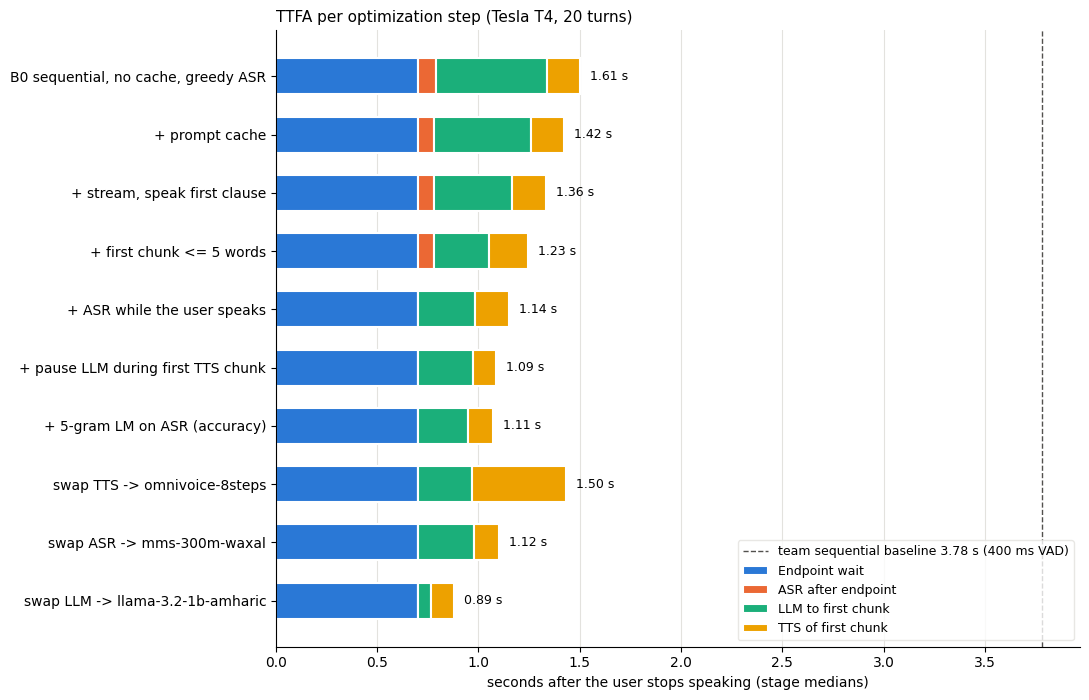

In [ ]:
# ---- Chart: where the time goes at each step (colours validated for colour-blind readers) ----
if RUN_E2E and len(E2E_ROWS):
    stages = [("endpoint_wait", "Endpoint wait", "#2a78d6"), ("asr_after_endpoint", "ASR after endpoint", "#eb6834"),
              ("llm_to_chunk", "LLM to first chunk", "#1baf7a"), ("tts_chunk", "TTS of first chunk", "#eda100")]
    S = E2E_SUMMARY
    fig, ax = plt.subplots(figsize=(11, 0.55 * len(S) + 1.6))
    left = np.zeros(len(S))
    for col, label, color in stages:
        ax.barh(range(len(S)), S[col], left=left, color=color, edgecolor="white", linewidth=1.5, label=label, height=0.62)
        left += S[col].values
    for i, v in enumerate(S.ttfa_med):
        ax.text(left[i] + 0.05, i, f"{v:.2f} s", va="center", fontsize=9)
    ax.axvline(TEAM_BASELINE["ttfa_s"], color="#52514e", linestyle="--", linewidth=1,
               label=f"team sequential baseline {TEAM_BASELINE['ttfa_s']} s (400 ms VAD)")
    ax.set_yticks(range(len(S))); ax.set_yticklabels(S.index); ax.invert_yaxis()
    ax.set_xlabel("seconds after the user stops speaking (stage medians)")
    ax.spines[["top", "right"]].set_visible(False); ax.grid(axis="x", color="#e3e2de"); ax.set_axisbelow(True)
    ax.legend(loc="lower right", frameon=True, facecolor="white", edgecolor="#e3e2de", fontsize=9)
    ax.set_title(f"TTFA per optimization step ({GPU_NAME}, {len(TURNS)} turns)", fontsize=11, loc="left")
    plt.tight_layout(); plt.savefig(RESULTS / "ttfa_ladder.png", dpi=150, bbox_inches="tight"); plt.show()

## 8. Talk to it (microphone demo)
Uses the fastest configuration from the ladder. Record a question, stop, and the answer plays automatically. The timing shown is computed from when recording stops (no silence wait, because you press stop), so it is lower than the TTFA above by the 0.7 s endpoint wait.

In [ ]:
def speak_full_reply(pipe, text):
    """First chunk as in the ladder, then the rest of the reply (at most MAX_SENTENCES) resumed from the KV cache."""
    first = pipe.respond(text)
    audio, reply = [first["audio"]], first["chunk"]
    prompt = pipe.srv.template(chat_messages(text)) + reply
    rest, gen = "", pipe.srv.stream(prompt, MAX_TOKENS, cache=True)
    try:
        for p in gen:
            if isinstance(p, dict): break
            rest += p
            if len(SENT_END.findall(reply + rest)) >= MAX_SENTENCES: break
    finally:
        gen.close()
    if rest.strip():
        w, _ = pipe.tts.synth(rest); audio.append(w)
    return first, reply + rest, np.concatenate([a for a in audio if len(a)]) if any(len(a) for a in audio) else np.zeros(1600, np.float32)

if RUN_DEMO:
    import gradio as gr
    DEMO_SRV = LlamaServer(MAIN_LLM, port=8330).start()
    DEMO = S2S(ASR_E2E[E2E_ASR] if RUN_E2E else CtcAsr(E2E_ASR, ASR_PATHS[E2E_ASR]), DEMO_SRV, MMS, **BEST)
    def answer(mic):
        if mic is None: return None, "", "", "no audio received"
        sr, a = mic
        a = a.astype(np.float32); a = a.mean(1) if a.ndim > 1 else a
        if np.abs(a).max() > 1.5: a /= 32768.0
        a = resample(a, sr, 16000)
        t = now(); heard, _ = DEMO.asr.transcribe(a, True); t_asr = now() - t
        first, reply, audio = speak_full_reply(DEMO, heard or "ሰላም")
        ready = t_asr + first["after_asr_s"]
        return ((DEMO.tts.sr, audio), heard, reply,
                f"first audio ready {ready:.2f} s after you stopped: ASR {t_asr:.2f} + LLM {first['llm_to_chunk_s']:.2f} + TTS {first['tts_chunk_s']:.2f} s")
    gr.Interface(fn=answer, inputs=gr.Audio(sources=["microphone"], type="numpy", label="Ask in Amharic"),
                 outputs=[gr.Audio(label="Answer", autoplay=True), gr.Textbox(label="Heard"), gr.Textbox(label="Answer text"), gr.Textbox(label="Timing")],
                 title="Amharic voice assistant — latency-optimised cascade",
                 description=f"ASR {E2E_ASR}{' + 5-gram LM' if HAVE_KENLM else ''} · LLM {MAIN_LLM} (llama.cpp 4-bit) · MMS-TTS").launch(share=IN_COLAB, debug=False)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://268160ae2fd9a1c80a.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


## 9. Save everything and summarise

In [ ]:
def save(name, df):
    if isinstance(df, pd.DataFrame) and len(df):
        df.to_csv(RESULTS / f"{name}.csv", index=not isinstance(df.index, pd.RangeIndex))
for name, obj in [("asr_clips", ASR_CLIPS.drop(columns=[c for c in ("audio",) if c in getattr(ASR_CLIPS, "columns", [])]) if RUN_ASR else None),
                  ("asr_summary", ASR_SUMMARY if RUN_ASR else None), ("asr_models", ASR_META if RUN_ASR else None),
                  ("llm_replies", LLM_REPLIES if RUN_LLM else None), ("llm_summary", LLM_SUMMARY if RUN_LLM else None),
                  ("gemma_diagnostics", GEMMA_DIAG if isinstance(GEMMA_DIAG, pd.DataFrame) else None),
                  ("tts_sentences", TTS_ROWS if RUN_TTS else None), ("tts_summary", TTS_SUMMARY if RUN_TTS else None),
                  ("e2e_turns", E2E_ROWS if RUN_E2E else None), ("e2e_summary", E2E_SUMMARY if RUN_E2E else None)]:
    save(name, obj)
ENV = dict(run_id=RUN_ID, gpu=GPU_NAME, device=DEVICE, torch=torch.__version__, llama_cpp=LLAMA_TAG, smoke_test=SMOKE_TEST, seed=SEED,
           hangover_ms=HANGOVER_MS, seg_pause_ms=SEG_PAUSE_MS, first_chunk_words=FIRST_CHUNK_WORDS, max_tokens=MAX_TOKENS,
           asr_models=list(ASR_PATHS), llms=list(LLMS), main_llm=MAIN_LLM, omnivoice=OMNI is not None, n_fleurs=N_FLEURS,
           n_questions=len(QUESTIONS), n_turns=len(TURNS), team_baseline=TEAM_BASELINE)
(RESULTS / "environment.json").write_text(json.dumps(ENV, indent=2, ensure_ascii=False))

lines = [f"# Latency track results — {RUN_ID} ({GPU_NAME})", ""]
if RUN_E2E and len(E2E_ROWS):
    b0, best = E2E_SUMMARY.iloc[0], E2E_SUMMARY.loc[LADDER[-1][0]]
    lines += [f"* **TTFA: {b0.ttfa_med:.2f} s -> {best.ttfa_med:.2f} s** median ({best.ttfa_med / b0.ttfa_med - 1:+.0%}) with {HANGOVER_MS} ms endpoint wait; "
              f"{best.ttfa_vad400_med:.2f} s with the team's 400 ms assumption (team sequential baseline {TEAM_BASELINE['ttfa_s']} s).",
              f"* Final stage medians: endpoint {best.endpoint_wait:.2f} s, ASR after endpoint {best.asr_after_endpoint:.2f} s, "
              f"LLM to first chunk {best.llm_to_chunk:.2f} s, TTS {best.tts_chunk:.2f} s."]
if RUN_ASR:
    s = ASR_SUMMARY[ASR_SUMMARY.condition == "fleurs_clean"].set_index(["model", "decoder"])
    for m in ASR_PATHS:
        if HAVE_KENLM:
            lines.append(f"* ASR {m} (FLEURS clean): WER {s.loc[(m, 'greedy'), 'WER']:.3f} greedy -> {s.loc[(m, '5-gram LM'), 'WER']:.3f} with the 5-gram LM; "
                         f"{s.loc[(m, '5-gram LM, cut at pauses'), 'WER']:.3f} when cut at pauses.")
        else:
            lines.append(f"* ASR {m} (FLEURS clean): WER {s.loc[(m, 'greedy'), 'WER']:.3f} greedy (no LM: kenlm did not install); "
                         f"{s.loc[(m, 'greedy, cut at pauses'), 'WER']:.3f} when cut at pauses.")
if RUN_LLM:
    for m, r in LLM_SUMMARY.iterrows():
        bb = f", Belebele {r.belebele_acc:.3f}" if "belebele_acc" in r and not pd.isna(r.belebele_acc) else ""
        lines.append(f"* LLM {m}: first token {r.ttft_warm_s:.2f} s warm ({r.ttft_cold_s:.2f} s cold), first speakable chunk {r.first_chunk_s:.2f} s, "
                     f"{r.decode_tok_s:.0f} tok/s, keyword hits {r.keyword_hit_rate:.0%}{bb}.")
if RUN_TTS:
    for m, r in TTS_SUMMARY.iterrows():
        lines.append(f"* TTS {m}: first chunk {r.first_chunk_ms_med:.0f} ms, RTF {r.rtf_med:.3f}, round-trip CER {r.roundtrip_CER:.3f}.")
SUMMARY_MD = "\n".join(lines)
(RESULTS / "summary.md").write_text(SUMMARY_MD)
display(Markdown(SUMMARY_MD))
print("saved to", RESULTS)
if IN_COLAB and not USE_DRIVE:                                  # no Drive: hand the results over as a zip
    archive = shutil.make_archive(str(ROOT / f"results_{RUN_ID}"), "zip", RESULTS)
    from google.colab import files
    files.download(archive)
    print("downloading", archive)

# Latency track results — 20260929-185801 (Tesla T4)

* **TTFA: 1.61 s -> 1.11 s** median (-31%) with 700 ms endpoint wait; 0.81 s with the team's 400 ms assumption (team sequential baseline 3.78 s).
* Final stage medians: endpoint 0.70 s, ASR after endpoint 0.00 s, LLM to first chunk 0.25 s, TTS 0.12 s.
* ASR mms-300m-waxal (FLEURS clean): WER 0.277 greedy -> 0.225 with the 5-gram LM; 0.236 when cut at pauses.
* ASR ethio-asr-amharic (FLEURS clean): WER 0.169 greedy -> 0.158 with the 5-gram LM; 0.183 when cut at pauses.
* LLM llama-3.2-1b-amharic: first token 0.01 s warm (0.03 s cold), first speakable chunk 0.07 s, 128 tok/s, keyword hits 15%, Belebele 0.205.
* LLM gemma-4-e2b: first token 0.03 s warm (0.08 s cold), first speakable chunk 0.29 s, 64 tok/s, keyword hits 40%, Belebele 0.520.
* TTS mms-tts: first chunk 156 ms, RTF 0.024, round-trip CER 0.228.
* TTS mms-tts (no normaliser): first chunk 118 ms, RTF 0.026, round-trip CER 0.421.
* TTS omnivoice-8steps: first chunk 613 ms, RTF 0.071, round-trip CER 0.143.
* TTS omnivoice-16steps: first chunk 1045 ms, RTF 0.122, round-trip CER 0.066.

saved to /content/drive/MyDrive/Amharic_S2S_Latency/results/20260929-185801


## How to read the results
* **Compare against B0 on the same hardware**, not against numbers from other machines. The ladder is the evidence for each Week-7 decision: keep a change if it lowers median TTFA without raising ASR CER, lowering keyword hits, or hurting round-trip CER.
* **The endpoint wait is a setting, not a measurement.** Lowering it below ~700 ms made the system cut Amharic speakers off in the Week-6 tests; an Amharic end-of-turn model is the way to shrink it safely.
* **Keyword hits are a rough screen.** Fill in `llm_rating_sheet.csv` with native speakers before claiming one LLM answers better than another.
* **Synthetic questions flatter ASR.** Put real recordings in `my_turns/` for the final evaluation (the assignment asks for unseen speakers, noise, names, numbers and code-switching).